# Laboratory Exercise 2: Hotel Bookings

Lakeside Stay is a hotel on the shore of Lake Ohrid that takes bookings directly, through online agencies, and through travel agencies. Its export in `data/bookings.csv` holds one row per booking, and `data/new-bookings.csv` counts the bookings made on each day. The bookings are synthetic and describe no real guest, hotel, or agency.

The columns of `bookings.csv` are these:

- `booking_id`, the identifier of the booking, and `booked_on`, the day it was made,
- `country`, the guest's country, and `channel`, which is direct, an online agency, or a travel agency,
- `booking_type`, an individual or a group booking, and `guests`, the number of guests as the booking system recorded it,
- `room_class`, one of economy, standard, superior, deluxe, and suite, and `room_area`, the area of the room in square metres,
- `meal_plan`, the meals included, and `payment`, which is prepaid, a deposit, or pay at hotel, with `deposit`, the amount paid in advance in euros,
- `nightly_rate`, the price of a room for one night in euros, `nights`, the length of the stay, and `lead_time_days`, the days between the booking and the arrival,
- `extras_spend`, the euros spent on extras during the stay, and
- `rating`, the guest's rating of the stay from 1 to 10, which a later model will predict.

The bookings are to be prepared for that model: every gap filled for a reason, every unusual value understood, every label turned into numbers, and every column brought to a comparable scale, with every step learned from the training bookings alone. No request asks for a model.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, MissingIndicator, SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import (MinMaxScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer, RobustScaler,
                                   StandardScaler)

DATA = Path("../data")
# Every random step uses this seed, so a rerun gives the same result.
SEED = 2026

In [2]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [3]:
class FrequencyEncoder(TransformerMixin, BaseEstimator):
    """Replaces each category with its share of the rows passed to fit, and an unseen category with 0."""

    def fit(self, X: pd.DataFrame, y: object = None) -> "FrequencyEncoder":
        self.shares_ = {column: X[column].value_counts(normalize=True) for column in X.columns}
        return self

    def transform(self, X: pd.DataFrame) -> np.ndarray:
        return np.column_stack([X[column].map(share).fillna(0).to_numpy(dtype=float)
                                for column, share in self.shares_.items()])

    def get_feature_names_out(self, input_features: object = None) -> np.ndarray:
        return np.array([f"{column}_frequency" for column in self.shares_])

In [4]:
bookings = pd.read_csv(DATA / "bookings.csv")
new_bookings = pd.read_csv(DATA / "new-bookings.csv")
bookings.head()

,booking_id,booked_on,country,booking_type,channel,room_class,meal_plan,payment,guests,room_area,nightly_rate,nights,lead_time_days,deposit,extras_spend,rating
0,52001,2025-10-03,Bulgaria,individual,online agency,standard,full board,pay at hotel,3,21.4,56,5,28,unknown,27,8.7
1,52002,2025-10-05,Greece,individual,travel agency,economy,breakfast,deposit,1,16.2,42,2,12,30,0,9.0
2,52003,2025-10-07,Serbia,individual,travel agency,deluxe,half board,deposit,4,34.5,80,2,71,100,22,9.0
3,52004,2025-10-09,Serbia,individual,online agency,deluxe,half board,prepaid,4,32.7,unknown,6,3,940,0,8.1
4,52005,2025-10-09,Italy,individual,direct,standard,breakfast,prepaid,2,21.6,52,3,16,280,74,7.5


## Task 1: The Gaps

### 1.1 Reading the Gaps

The file writes a value it does not have with a marker of its own. Read the bookings into a table named `df` in which every such value is missing. Count the missing values in each column, and show where they fall.

In [5]:
pd.set_option("display.max_columns", 30)

# the file writes a missing value as "unknown"
df = pd.read_csv(DATA / "bookings.csv", na_values=["unknown"], parse_dates=["booked_on"])

gap_counts = df.isna().sum()
print("bookings with at least one gap:", df.isna().any(axis=1).sum())
gap_counts

bookings with at least one gap: 159


booking_id         0
booked_on          0
country            0
booking_type       0
channel            0
room_class         0
meal_plan         19
payment            0
guests             0
room_area          0
nightly_rate      85
nights            26
lead_time_days     0
deposit           54
extras_spend       0
rating             8
dtype: int64

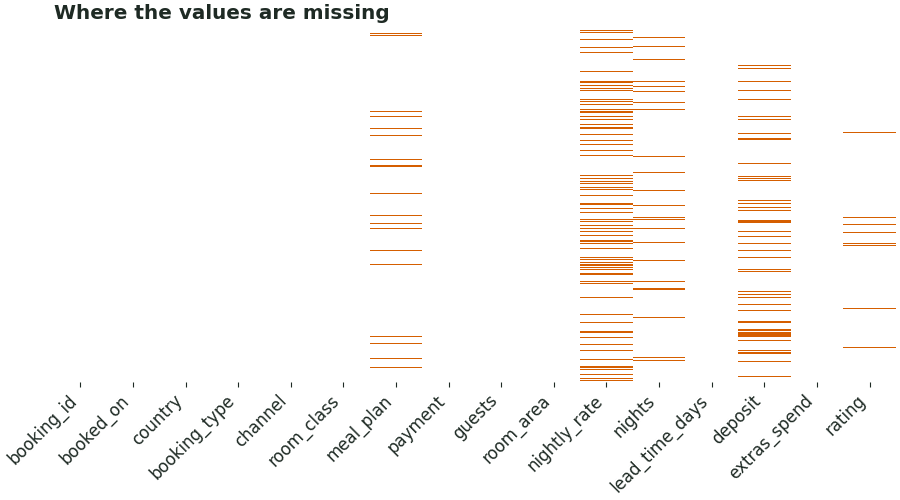

In [6]:
# where the gaps fall: every orange cell is a missing value
plt.figure(figsize=(9, 5))
sns.heatmap(df.isna().astype(int), cmap=["#ffffff", PALETTE[1]], cbar=False, yticklabels=False)
plt.grid(False)
plt.xticks(rotation=45, ha="right")
plt.title("Where the values are missing")
plt.show()

Five columns have gaps: `nightly_rate` (85), `deposit` (54), `nights` (26), `meal_plan` (19) and `rating` (8). The other columns are complete. In total 159 of the 400 bookings have at least one gap.

### 1.2 Why Values Are Missing

For each column with missing values, find out whether its gaps depend on another column, whether a gap means that the value does not exist, or whether the gaps follow no pattern. Show the comparison that decides each case.

In [7]:
# deposit: do the gaps depend on the payment type?
pd.crosstab(df["payment"], df["deposit"].isna(), colnames=["deposit is missing"])

deposit is missing,False,True
payment,,
deposit,151,0
pay at hotel,0,54
prepaid,195,0


In [8]:
# nightly_rate: share of gaps in every channel
rate_gap = df.groupby("channel")["nightly_rate"].agg(
    bookings="size", gaps=lambda s: s.isna().sum(), share=lambda s: s.isna().mean().round(3))
rate_gap

,bookings,gaps,share
channel,,,
direct,124,4,0.032
online agency,110,5,0.045
travel agency,166,76,0.458


In [9]:
# nights, meal_plan and rating: share of gaps inside the groups of other columns
def gap_share(column):
    parts = {by: df[column].isna().groupby(df[by]).mean() for by in ["channel", "room_class", "payment", "booking_type"]}
    return pd.concat(parts)

print("share of gaps in the whole column:")
print(df[["nights", "meal_plan", "rating"]].isna().mean().round(3))
pd.DataFrame({column: gap_share(column) for column in ["nights", "meal_plan", "rating"]}).round(3)

share of gaps in the whole column:
nights       0.065
meal_plan    0.048
rating       0.020
dtype: float64


nights  meal_plan  rating
channel      direct          0.073      0.040   0.048
             online agency   0.055      0.036   0.018
             travel agency   0.066      0.060   0.000
room_class   deluxe          0.100      0.025   0.075
             economy         0.038      0.019   0.000
             standard        0.071      0.047   0.024
             suite           0.050      0.075   0.025
             superior        0.061      0.061   0.000
payment      deposit         0.079      0.060   0.020
             pay at hotel    0.037      0.056   0.019
             prepaid         0.062      0.036   0.021
booking_type group           0.077      0.154   0.000
             individual      0.065      0.044   0.021

- **deposit**: the value does not exist. All the gaps are `pay at hotel` bookings and no other payment type has a gap, so nothing was paid in advance.
- **nightly_rate**: depends on another column. Almost half of the travel agency bookings have no rate, but only a few direct and online agency bookings.
- **nights**: no pattern. The share of gaps stays near the share of the whole column (about 6.5%) in every channel, room class, payment type and booking type.
- **meal_plan**: no pattern. The shares stay small in all groups. Group bookings look higher, but that is only 2 gaps among 13 group bookings, which is too few to say anything.
- **rating**: no clear pattern. There are only 8 gaps (6 of them in direct bookings), which is too few to tell a pattern. It does not matter for the decision, because these bookings are dropped anyway (1.3).

### 1.3 What Deleting Would Cost

Find out how many bookings would remain if every booking with a missing value were dropped, and how the mix of channels would change. Then decide what to do with the bookings that state no rating, and apply the decision to `df`.

In [10]:
complete = df.dropna()
n_bookings = len(df)
print("bookings:", len(df))
print("bookings left if every booking with a gap is dropped:", len(complete))
print("share lost:", round(1 - len(complete) / len(df), 3))

mix = pd.DataFrame({"all bookings": df["channel"].value_counts(normalize=True),
                    "complete bookings only": complete["channel"].value_counts(normalize=True)}).round(3)
mix

bookings: 400
bookings left if every booking with a gap is dropped: 241
share lost: 0.397


,all bookings,complete bookings only
channel,,
direct,0.310,0.369
online agency,0.275,0.336
travel agency,0.415,0.295


In [11]:
# rating is what the model has to predict, so a booking without it is dropped
print("bookings without a rating:", df["rating"].isna().sum())
df = df.dropna(subset=["rating"]).reset_index(drop=True)
print("bookings in df now:", len(df))

bookings without a rating: 8
bookings in df now: 392


Dropping every booking with a gap would lose about 40% of the bookings, and it would change the mix of channels: the travel agency share falls a lot (because their rates are often missing) while direct and online agency grow. So we do not delete in general, we fill the gaps instead.

The only bookings we drop are the 8 without a rating. The rating is the value that the later model has to predict, so filling it would mean inventing the answer. Only 8 of 400 bookings (2%) are lost.

## Task 2: The Split and the Fills

### 2.1 The Test Bookings

The bookings made on 1 July 2026 or later stand in for bookings that the preparation has never seen. Set them aside as the test bookings, `X_test` and `y_test`, and keep the earlier bookings as the training bookings, `X_train` and `y_train`, where `X` holds every column except the rating and `y` holds the rating. Every later step learns only from the training bookings. Report the number of each.

In [12]:
X = df.drop(columns="rating")
y = df["rating"]

is_test = df["booked_on"] >= "2026-07-01"
X_train, y_train = X[~is_test], y[~is_test]
X_test, y_test = X[is_test], y[is_test]

print("training bookings:", len(X_train), "| from", X_train["booked_on"].min().date(), "to", X_train["booked_on"].max().date())
print("test bookings:", len(X_test), "| from", X_test["booked_on"].min().date(), "to", X_test["booked_on"].max().date())

training bookings: 294 | from 2025-10-03 to 2026-06-29
test bookings: 98 | from 2026-07-01 to 2026-09-30


The split is by time and not random, because the test bookings play the role of bookings that come later.

### 2.2 Filling the Gaps

Fill the gaps of each column in the way its pattern calls for, learning every fill from the training bookings, and keep a record of the filled values wherever the absence itself carries information. Report the value that each fill by a single value uses.

In [13]:
# deposit: the value does not exist, so 0
# nights and meal_plan: no pattern, so the median and the most frequent value
# nightly_rate: depends on the channel. The median is only the first fill (2.3 tests better ones),
#               and the 0/1 column keeps a record of which rates were filled
fills = ColumnTransformer(
    [("deposit", SimpleImputer(strategy="constant", fill_value=0), ["deposit"]),
     ("nights", SimpleImputer(strategy="median"), ["nights"]),
     ("meal_plan", SimpleImputer(strategy="most_frequent"), ["meal_plan"]),
     ("nightly_rate", SimpleImputer(strategy="median"), ["nightly_rate"]),
     ("rate_was_missing", MissingIndicator(features="all"), ["nightly_rate"])],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

filled_train = fills.fit_transform(X_train)   # learned from the training bookings
filled_test = fills.transform(X_test)         # only applied to the test bookings

print("gaps left in the filled training table:", filled_train.isna().sum().sum())
print("gaps left in the filled test table:", filled_test.isna().sum().sum())
filled_train.head()

gaps left in the filled training table: 0
gaps left in the filled test table: 0


,deposit,nights,meal_plan,nightly_rate,missingindicator_nightly_rate
0,0.0,5.0,full board,56.0,False
1,30.0,2.0,breakfast,42.0,False
2,100.0,2.0,half board,80.0,False
3,940.0,6.0,half board,55.5,True
4,280.0,3.0,breakfast,52.0,False


In [14]:
# the value that every fill by a single value uses
fill_values = pd.Series({
    "deposit": fills.named_transformers_["deposit"].statistics_[0],
    "nights": fills.named_transformers_["nights"].statistics_[0],
    "meal_plan": fills.named_transformers_["meal_plan"].statistics_[0],
    "nightly_rate": fills.named_transformers_["nightly_rate"].statistics_[0],
}, name="fill value")
print(fill_values)

print()
print("filled rates recorded in the training bookings:", filled_train["missingindicator_nightly_rate"].sum())
print("filled rates recorded in the test bookings:", filled_test["missingindicator_nightly_rate"].sum())

deposit                 0
nights                4.0
meal_plan       breakfast
nightly_rate         55.5
Name: fill value, dtype: object

filled rates recorded in the training bookings: 66
filled rates recorded in the test bookings: 18


Every fill is learned from the training bookings only. The test bookings are filled with the same values.

- `deposit` gets 0 (no advance payment), `nights` gets the median, `meal_plan` gets the most frequent plan.
- Only `nightly_rate` gets a record of the filled values. Its gaps depend on the channel, so the gap itself tells something. For `nights` and `meal_plan` the gaps follow no pattern, and `deposit` already shows it with the 0 (and with the payment column).
- The median rate is only the first fill. In 2.3 it is compared with two better ways.

### 2.3 How Well a Fill Recovers the Rate

Hide the known nightly rate of every training booking whose identifier is divisible by five. Fill these rates back in three ways, all from the numeric columns: with the median rate, from the five most similar bookings judged on standardized columns, and by predicting each column from the others in rounds with the seed 2026. Measure how far each fill lies from the true rates on average, and show the filled rates against the true ones.

In [15]:
numeric = ["guests", "room_area", "nightly_rate", "nights", "lead_time_days", "deposit", "extras_spend"]

# hide the known rates of the training bookings whose id is divisible by five
hidden = (X_train["booking_id"] % 5 == 0) & X_train["nightly_rate"].notna()
true_rates = X_train.loc[hidden, "nightly_rate"].to_numpy()
masked = X_train[numeric].copy()
masked.loc[hidden, "nightly_rate"] = np.nan
rate_col = numeric.index("nightly_rate")
print("hidden rates:", hidden.sum())

# 1) median
median_fill = SimpleImputer(strategy="median").fit_transform(masked)

# 2) five most similar bookings, judged on standardized columns
scaler = StandardScaler().fit(masked)
knn_fill = scaler.inverse_transform(KNNImputer(n_neighbors=5).fit_transform(scaler.transform(masked)))

# 3) every column predicted from the others in rounds
iterative_fill = IterativeImputer(random_state=SEED).fit_transform(masked)

predicted = {
    "median": median_fill[hidden.to_numpy(), rate_col],
    "5 nearest neighbours": knn_fill[hidden.to_numpy(), rate_col],
    "iterative": iterative_fill[hidden.to_numpy(), rate_col],
}
mae = pd.Series({name: np.abs(values - true_rates).mean() for name, values in predicted.items()},
                name="mean absolute error (EUR)")
mae.round(2)

hidden rates: 48


median                  10.58
5 nearest neighbours     4.46
iterative                3.47
Name: mean absolute error (EUR), dtype: float64

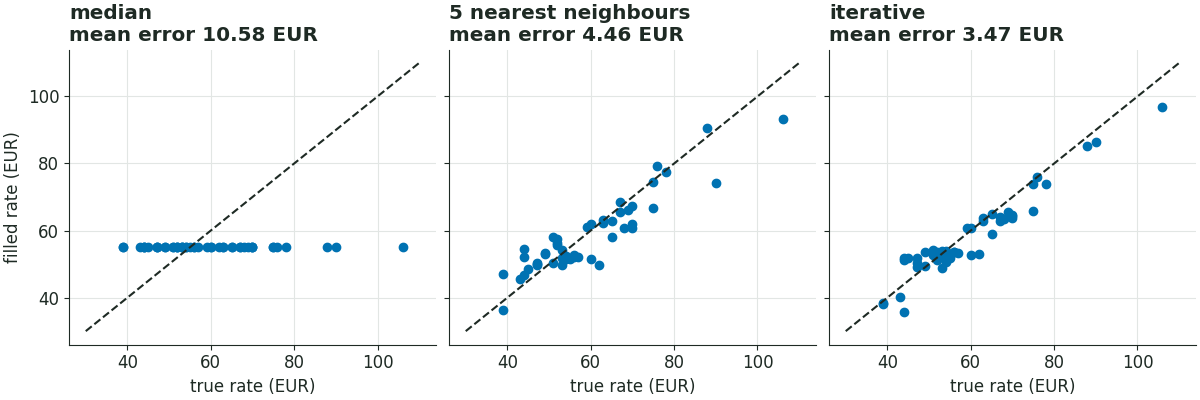

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, (name, values) in zip(axes, predicted.items()):
    ax.scatter(true_rates, values, color=PALETTE[0])
    ax.plot([30, 110], [30, 110], color=INK, linestyle="--")   # a perfect fill lies on this line
    ax.set_title(f"{name}\nmean error {mae[name]:.2f} EUR")
    ax.set_xlabel("true rate (EUR)")
axes[0].set_ylabel("filled rate (EUR)")
plt.show()

In [17]:
# extra check: the iterative fill with only the rate and the room area
area_fill = IterativeImputer(random_state=SEED).fit_transform(masked[["nightly_rate", "room_area"]])
print("iterative from the room area only:", np.abs(area_fill[hidden.to_numpy(), 0] - true_rates).mean().round(2))

iterative from the room area only: 3.33


The median gives the same rate to every hidden booking, so its points lie on one horizontal line and the error is the largest. The five nearest neighbours are much better, and the iterative fill is the best, with the smallest average error. The rate mostly depends on the room (its area), and the two model based fills use this, while the median ignores it.

For the final preparation the nightly rate is therefore filled in rounds. The extra check shows that the room area alone is enough, so the final fill uses only the rate and the room area.

### 2.4 Gaps in Time

`new_bookings` counts the bookings made on each day, and a day without a row was not recorded. Make every day of the period visible, then fill each gap from the neighbouring days, at most three days into a gap and only between recorded days. Report how many days are missing before the fill and how many stay missing after it, and show the series around its longest gap.

In [18]:
# every day of the period gets a row, a day that was not recorded becomes missing
new_bookings["date"] = pd.to_datetime(new_bookings["date"])
daily = new_bookings.set_index("date")["new_bookings"]
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_days)
print("days in the period:", len(all_days))
print("days missing before the fill:", daily.isna().sum())

# fill from the neighbouring days: at most 3 days into a gap, and only between recorded days
daily_filled = daily.interpolate(method="linear", limit=3, limit_area="inside")
print("days missing after the fill:", daily_filled.isna().sum())

days in the period: 180
days missing before the fill: 24
days missing after the fill: 5


In [19]:
# the longest gap
gap_number = daily.notna().cumsum()                              # a recorded day and the gap after it share a number
gap_length = daily.isna().groupby(gap_number).transform("sum")   # length of the gap every missing day belongs to
gap_days = daily.index[daily.isna() & (gap_length == gap_length.max())]
print("longest gap:", gap_length.max(), "days, from", gap_days[0].date(), "to", gap_days[-1].date())

around = slice(gap_days[0] - pd.Timedelta(days=5), gap_days[-1] + pd.Timedelta(days=5))
pd.DataFrame({"recorded": daily[around], "after the fill": daily_filled[around]})

longest gap: 8 days, from 2026-05-28 to 2026-06-04


,recorded,after the fill
2026-05-23,11.0,11.000000
2026-05-24,7.0,7.000000
2026-05-25,5.0,5.000000
2026-05-26,5.0,5.000000
2026-05-27,10.0,10.000000
2026-05-28,NaN,9.333333
2026-05-29,NaN,8.666667
2026-05-30,NaN,8.000000
2026-05-31,NaN,NaN
2026-06-01,NaN,NaN


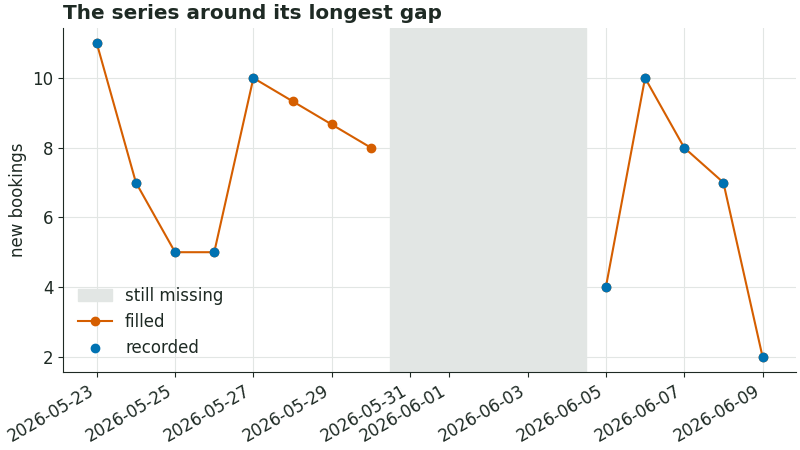

In [20]:
window = daily_filled[around]
still_missing = window.index[window.isna()]

fig, ax = plt.subplots()
ax.axvspan(still_missing[0] - pd.Timedelta(hours=12), still_missing[-1] + pd.Timedelta(hours=12),
           color=GRID, label="still missing")
ax.plot(window.index, window, color=PALETTE[1], marker="o", label="filled")
ax.plot(daily[around].index, daily[around], color=PALETTE[0], marker="o", linestyle="none", label="recorded")
ax.set_ylabel("new bookings")
ax.set_title("The series around its longest gap")
ax.legend()
fig.autofmt_xdate()
plt.show()

The period has 180 days but only 156 have a row, so 24 days were missing. The linear fill between the neighbouring days, limited to 3 days and to the days between recorded days, fills 19 of them and leaves 5 missing. These 5 days belong to the longest gap (8 days, 28 May to 4 June): only its first 3 days are filled, because the limit of 3 days stops the fill.

## Task 3: Outliers

### 3.1 Unusual Numbers of Guests

Flag the unusual numbers of guests among the training bookings in two ways: as more than 1.5 interquartile ranges beyond the quartiles, and as more than three standard deviations from the mean. Report how many bookings each way flags, show them, and explain why the two ways disagree.

In [21]:
guests = X_train["guests"]

# 1.5 interquartile ranges beyond the quartiles
q1, q3 = guests.quantile([0.25, 0.75])
iqr = q3 - q1
low_limit, high_limit = q1 - 1.5 * iqr, q3 + 1.5 * iqr
flag_iqr = (guests < low_limit) | (guests > high_limit)

# more than 3 standard deviations from the mean
mean, std = guests.mean(), guests.std()
flag_sigma = (guests - mean).abs() > 3 * std

print(f"quartiles {q1} and {q3}, IQR {iqr}, limits {low_limit} and {high_limit}")
print(f"mean {mean:.2f}, std {std:.2f}, limits {mean - 3 * std:.2f} and {mean + 3 * std:.2f}, median {guests.median()}")
print("flagged by the IQR rule:", flag_iqr.sum())
print("flagged by the 3 sigma rule:", flag_sigma.sum())

quartiles 2.0 and 3.0, IQR 1.0, limits 0.5 and 4.5
mean 6.49, std 29.62, limits -82.36 and 95.34, median 2.0
flagged by the IQR rule: 14
flagged by the 3 sigma rule: 4


In [22]:
flagged = X_train.loc[flag_iqr | flag_sigma, ["booking_id", "booking_type", "channel", "room_class", "guests"]]
flagged = flagged.assign(iqr_rule=flag_iqr, sigma_rule=flag_sigma).sort_values("guests")
flagged

,booking_id,booking_type,channel,room_class,guests,iqr_rule,sigma_rule
19,52020,group,travel agency,standard,15,True,False
267,52274,group,travel agency,standard,15,True,False
277,52284,group,travel agency,standard,16,True,False
289,52296,group,travel agency,standard,22,True,False
261,52268,group,travel agency,standard,26,True,False
94,52095,group,travel agency,standard,29,True,False
169,52171,group,travel agency,standard,31,True,False
218,52221,group,travel agency,standard,35,True,False
273,52280,group,travel agency,standard,35,True,False
292,52299,group,travel agency,standard,39,True,False


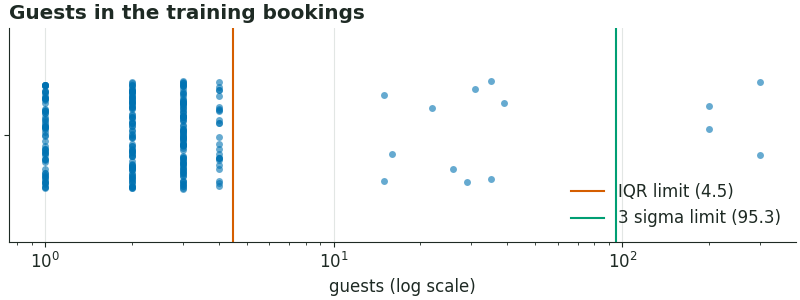

In [23]:
plt.figure(figsize=(8, 3))
sns.stripplot(x=guests, jitter=0.25, alpha=0.6, color=PALETTE[0])
plt.xscale("log")
plt.axvline(high_limit, color=PALETTE[1], label=f"IQR limit ({high_limit})")
plt.axvline(mean + 3 * std, color=PALETTE[2], label=f"3 sigma limit ({mean + 3 * std:.1f})")
plt.xlabel("guests (log scale)")
plt.title("Guests in the training bookings")
plt.legend()
plt.show()

The IQR rule flags 14 bookings and the 3 sigma rule only 4. The two disagree because the mean and the standard deviation are pulled by the extreme values themselves: the four bookings with 200 and 300 guests push the mean to 6.5 and the standard deviation to 29.6, so the 3 sigma limit (95.3) lies above every group booking and only the four largest values are flagged. The quartiles (2 and 3) do not move because of a few extreme values, so the IQR limit stays at 4.5 and flags every number above it.

### 3.2 Errors or Genuine Values

Decide for each flagged number of guests whether it is an error or a genuine value, and handle it accordingly in `X`, `X_train`, and `X_test`.

In [24]:
# what kind of bookings are the flagged ones?
flagged.groupby("booking_type")["guests"].agg(["count", "min", "max"])

,count,min,max
booking_type,,,
group,10,15,39
individual,4,200,300


In [25]:
# the largest number of guests in an individual booking that was not flagged
print(X_train.loc[(X_train["booking_type"] == "individual") & ~(flag_iqr | flag_sigma), "guests"].max())

4


In [26]:
# an individual booking with more than 4 guests is an error, so it becomes a missing value
def fix_guests(table):
    table = table.copy()
    error = (table["booking_type"] == "individual") & (table["guests"] > 4)
    table.loc[error, "guests"] = np.nan
    return table

X, X_train, X_test = fix_guests(X), fix_guests(X_train), fix_guests(X_test)
print("missing guests in X:", X["guests"].isna().sum())
print("missing guests in X_train:", X_train["guests"].isna().sum())
print("missing guests in X_test:", X_test["guests"].isna().sum())

missing guests in X: 4
missing guests in X_train: 4
missing guests in X_test: 0


- The 10 flagged **group** bookings (15 to 39 guests) are genuine values. A group booking is made for many guests, and the number fits the booking type.
- The 4 flagged **individual** bookings (200 and 300 guests) are errors. One individual booking cannot hold 200 guests, and every other individual booking has 1 to 4 guests. They could be typing errors (2 and 3 with extra zeros), but we cannot know it.

The errors become missing values in `X`, `X_train` and `X_test` with the same rule (no learning is needed). All four are training bookings, the test bookings have none. They are filled later in the preparation, with the median of the training bookings.

### 3.3 Unusual Combinations

Among the training bookings of individual guests with a known nightly rate, find the bookings whose combination of room area and nightly rate is unusual, in two ways: by how quickly random splits isolate a booking, and by how much sparser its neighbourhood is than the neighbourhoods of its neighbours. Judge both on the two columns standardized, treat 2% of the bookings as unusual, use 20 neighbours, and use the seed 2026. Decide what to do with the bookings that both ways flag.

In [27]:
candidates = X_train[(X_train["booking_type"] == "individual") & X_train["nightly_rate"].notna()]
Z = StandardScaler().fit_transform(candidates[["room_area", "nightly_rate"]])

# 1) how quickly random splits isolate a booking
flag_forest = IsolationForest(contamination=0.02, random_state=SEED).fit_predict(Z) == -1
# 2) how much sparser its neighbourhood is than the neighbourhoods of its neighbours
flag_lof = LocalOutlierFactor(n_neighbors=20, contamination=0.02).fit_predict(Z) == -1
flag_both = flag_forest & flag_lof

print("bookings judged:", len(candidates))
print("isolation forest flags:", flag_forest.sum())
print("local outlier factor flags:", flag_lof.sum())
print("both flag:", flag_both.sum())

bookings judged: 222
isolation forest flags: 5
local outlier factor flags: 5
both flag: 3


In [28]:
unusual = candidates[flag_forest | flag_lof][["booking_id", "room_class", "room_area", "nightly_rate", "channel"]].copy()
unusual["rating"] = y_train[unusual.index]
unusual["isolation_forest"] = flag_forest[flag_forest | flag_lof]
unusual["lof"] = flag_lof[flag_forest | flag_lof]
unusual

,booking_id,room_class,room_area,nightly_rate,channel,rating,isolation_forest,lof
57,52058,superior,28.6,75.0,online agency,8.1,False,True
104,52105,standard,21.4,62.0,online agency,7.8,False,True
121,52123,suite,42.8,33.0,direct,9.1,True,True
129,52131,suite,45.3,104.0,travel agency,10.0,True,False
176,52178,suite,43.3,34.0,online agency,8.6,True,True
246,52253,suite,42.8,36.0,online agency,9.4,True,True
293,52300,suite,45.5,106.0,travel agency,8.7,True,False


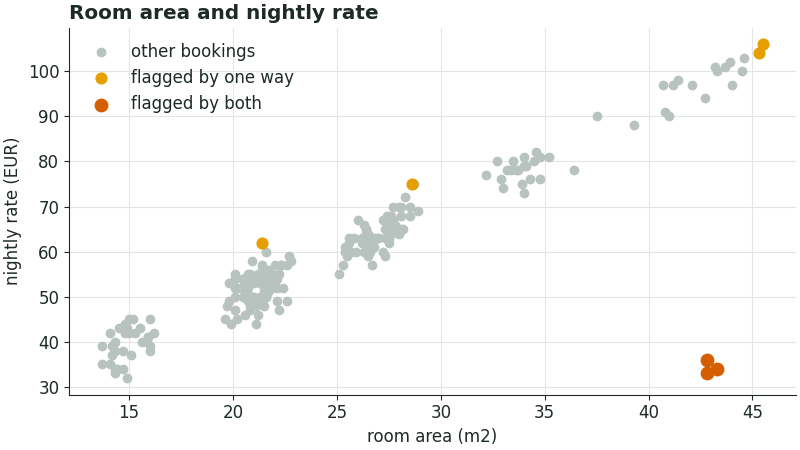

In [29]:
plt.figure()
only_one = (flag_forest | flag_lof) & ~flag_both
plt.scatter(candidates["room_area"], candidates["nightly_rate"], color="#b8c2be", label="other bookings")
plt.scatter(candidates.loc[only_one, "room_area"], candidates.loc[only_one, "nightly_rate"], color=PALETTE[4], s=60, label="flagged by one way")
plt.scatter(candidates.loc[flag_both, "room_area"], candidates.loc[flag_both, "nightly_rate"], color=PALETTE[1], s=80, label="flagged by both")
plt.xlabel("room area (m2)")
plt.ylabel("nightly rate (EUR)")
plt.title("Room area and nightly rate")
plt.legend()
plt.show()

In [30]:
# what do the other suites cost?
other_suites = candidates[(candidates["room_class"] == "suite") & ~flag_both]
other_suites["nightly_rate"].describe()

count     17.0
mean      98.0
std        5.0
min       88.0
25%       97.0
50%       98.0
75%      101.0
max      106.0
Name: nightly_rate, dtype: float64

In [31]:
# drop the bookings that both ways flag from the training bookings (and from X, which holds all bookings)
drop_index = candidates.index[flag_both]
X, y = X.drop(index=drop_index), y.drop(index=drop_index)
X_train, y_train = X_train.drop(index=drop_index), y_train.drop(index=drop_index)
print("training bookings:", len(X_train), "| test bookings:", len(X_test), "| all bookings:", len(X))

training bookings: 291 | test bookings: 98 | all bookings: 389


Each way flags 5 bookings and 3 of them are flagged by both. All three are suites (about 43 m2) that cost 33 to 36 EUR a night, which is the price of an economy room, while the other 17 suites cost 88 to 106 EUR. Each value alone is normal (a suite has this area, and an economy room has this rate), only the combination is not, so the rate was probably recorded wrongly. We do not know the true rate, so the three bookings are dropped from the training bookings. This is only 3 of 294 bookings.

The bookings that only one way flags are kept: they are the two most expensive suites (104 and 106 EUR), a superior room at 75 EUR and a standard room at 62 EUR, which are the highest rates of their room classes. This is unusual but possible. Test bookings are never dropped, because they stand for new bookings.

### 3.4 Capping the Nights

Find the 1st and the 99th percentiles of the number of nights among the training bookings, and count the test bookings that lie beyond them. Decide whether to cap the nights at these bounds.

In [32]:
low, high = X_train["nights"].quantile([0.01, 0.99])
print("1st percentile:", low, "| 99th percentile:", high)
print("nights in the training bookings:", X_train["nights"].min(), "to", X_train["nights"].max())

beyond = X_test[(X_test["nights"] < low) | (X_test["nights"] > high)]
print("test bookings beyond the bounds:", len(beyond))
beyond[["booking_id", "booked_on", "room_class", "guests", "nights"]].assign(rating=y_test[beyond.index])

1st percentile: 1.0 | 99th percentile: 7.0
nights in the training bookings: 1.0 to 7.0
test bookings beyond the bounds: 8


,booking_id,booked_on,room_class,guests,nights,rating
301,52308,2026-07-12,standard,1.0,12.0,9.5
308,52315,2026-07-15,economy,1.0,14.0,7.8
309,52316,2026-07-16,standard,1.0,10.0,9.0
316,52324,2026-07-23,suite,4.0,11.0,7.0
318,52326,2026-07-25,economy,2.0,11.0,7.1
321,52329,2026-07-27,standard,1.0,11.0,9.6
348,52356,2026-08-22,deluxe,2.0,14.0,9.0
357,52366,2026-09-01,superior,2.0,13.0,9.2


The training bookings have 1 to 7 nights, so the bounds are 1 and 7. Eight test bookings lie beyond them, all with more than 7 nights (10 to 14).

**Decision: do not cap.** These stays are not errors. They were booked in July, August and September (the summer season), they look normal in every other column and their ratings are normal. Capping them at 7 would hide a real change in the data (the test bookings contain stays that the training bookings never had). The standardized nights simply get larger values for them.

## Task 4: Encoding and Scaling

### 4.1 Labels as Numbers

Turn every label into numbers in the way its kind calls for, learning from the training bookings:

- the room class keeps its order, from economy to suite,
- a label without an order gets one column per category, a single column when it has two categories, and zeros for a category that the training bookings never held, and
- the country becomes its share of the training bookings, with 0 for a country that the training bookings never held.

Report the code of each room class, the number of columns that the labels without an order become, and the share of Serbia.

In [33]:
import warnings

ROOM_ORDER = ["economy", "standard", "superior", "deluxe", "suite"]
nominal = ["booking_type", "channel", "meal_plan", "payment"]

# room class: keeps its order
room_encoder = OrdinalEncoder(categories=[ROOM_ORDER]).fit(X_train[["room_class"]])
room_codes = room_encoder.transform(pd.DataFrame({"room_class": ROOM_ORDER}))[:, 0]
print(dict(zip(ROOM_ORDER, room_codes.astype(int).tolist())))

{'economy': 0, 'standard': 1, 'superior': 2, 'deluxe': 3, 'suite': 4}


In [34]:
# labels without an order: one column per category, one column for two categories, zeros for an unseen category
# (the gaps of meal_plan are filled with the most frequent plan first)
label_encoder = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False),
).fit(X_train[nominal])

label_names = label_encoder.get_feature_names_out()
print("columns of the labels without an order:", len(label_names))
print(list(label_names))

# a channel that the training bookings never held gives zeros in the channel columns
example = pd.DataFrame({"booking_type": ["individual"], "channel": ["phone"], "meal_plan": ["breakfast"], "payment": ["prepaid"]})
with warnings.catch_warnings():
    warnings.simplefilter("ignore")          # sklearn warns about the unknown category, which is what we want to show
    unseen_row = label_encoder.transform(example)
pd.DataFrame(unseen_row, columns=label_names)

columns of the labels without an order: 11
['booking_type_individual', 'channel_direct', 'channel_online agency', 'channel_travel agency', 'meal_plan_breakfast', 'meal_plan_full board', 'meal_plan_half board', 'meal_plan_room only', 'payment_deposit', 'payment_pay at hotel', 'payment_prepaid']


,booking_type_individual,channel_direct,channel_online agency,channel_travel agency,meal_plan_breakfast,meal_plan_full board,meal_plan_half board,meal_plan_room only,payment_deposit,payment_pay at hotel,payment_prepaid
0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [35]:
# country: its share of the training bookings
country_encoder = FrequencyEncoder().fit(X_train[["country"]])
shares = country_encoder.shares_["country"]
print("countries in the training bookings:", len(shares))
print("share of Serbia:", round(shares["Serbia"], 4), "=", (X_train["country"] == "Serbia").sum(), "of", len(X_train))

# Israel is not in the training bookings, so its share is 0
country_encoder.transform(pd.DataFrame({"country": ["Israel", "Serbia"]}))

countries in the training bookings: 23
share of Serbia: 0.1615 = 47 of 291


array([[0.        ],
       [0.16151203]])

- The room class codes are economy 0, standard 1, superior 2, deluxe 3, suite 4.
- The labels without an order become **11 columns**: `booking_type` has two categories and gets 1 column, `channel` gets 3, `meal_plan` gets 4 and `payment` gets 3.
- The country becomes its share of the training bookings (23 countries). Serbia has 47 of the 291 training bookings, so its share is 0.1615. A country that the training bookings never held (Israel, South Korea) gets 0.

### 4.2 Comparable Scales

Bring every numeric column to a scale that suits it, and reduce the skew of the columns with a long right tail. Report the skew of the lead time before and after, the power that brings it closest to a normal distribution, and what the extras spend needs instead.

In [36]:
# skew of the numeric columns of the training bookings (the gaps are ignored)
X_train[numeric].skew().round(2)

guests            5.61
room_area         0.95
nightly_rate      0.95
nights           -0.09
lead_time_days    2.65
deposit           8.63
extras_spend      2.67
dtype: float64

In [37]:
# the columns with a long right tail (skew above 1) get a power transform, the others are standardized
# the fills of the gaps are part of every step, so the steps can be reused in the one preparation (5.1)
number_steps = [
    ("rate", make_pipeline(IterativeImputer(random_state=SEED), StandardScaler()), ["nightly_rate", "room_area"]),
    ("nights", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), ["nights"]),
    ("guests", make_pipeline(SimpleImputer(strategy="median"), PowerTransformer(method="yeo-johnson")), ["guests"]),
    ("deposit", make_pipeline(SimpleImputer(strategy="constant", fill_value=0), PowerTransformer(method="yeo-johnson")), ["deposit"]),
    ("lead_time", PowerTransformer(method="box-cox"), ["lead_time_days"]),
    ("extras", PowerTransformer(method="yeo-johnson"), ["extras_spend"]),
]
scaling = ColumnTransformer(number_steps, verbose_feature_names_out=False).set_output(transform="pandas")
scaled_train = scaling.fit_transform(X_train)[numeric]

skews = pd.DataFrame({"skew before": X_train[numeric].skew(), "skew after": scaled_train.skew()}).round(3)
skews

,skew before,skew after
guests,5.608,-0.041
room_area,0.947,0.947
nightly_rate,0.945,0.950
nights,-0.091,-0.086
lead_time_days,2.652,-0.000
deposit,8.628,-0.018
extras_spend,2.671,-0.090


In [38]:
print("lead time, skew before:", round(X_train["lead_time_days"].skew(), 3))
print("lead time, skew after:", round(scaled_train["lead_time_days"].skew(), 4))
print("Box-Cox power of the lead time:", scaling.named_transformers_["lead_time"].lambdas_[0].round(3))

# the extras spend has zeros, and Box-Cox needs strictly positive values
print()
print("bookings with no extras spend:", (X_train["extras_spend"] == 0).sum(), "of", len(X_train))
try:
    PowerTransformer(method="box-cox").fit(X_train[["extras_spend"]])
except ValueError as error:
    print("Box-Cox fails:", error)

# the powers of all four power transforms
lambdas = pd.Series({
    "lead_time_days (Box-Cox)": scaling.named_transformers_["lead_time"].lambdas_[0],
    "extras_spend (Yeo-Johnson)": scaling.named_transformers_["extras"].lambdas_[0],
    "guests (Yeo-Johnson)": scaling.named_transformers_["guests"][-1].lambdas_[0],
    "deposit (Yeo-Johnson)": scaling.named_transformers_["deposit"][-1].lambdas_[0],
}, name="power").round(3)
print()
print(lambdas)

# every scaled column has mean 0 and standard deviation 1
print()
print("largest absolute mean:", scaled_train.mean().abs().max().round(3))
print("standard deviations:", scaled_train.std().round(2).tolist())

lead time, skew before: 2.652
lead time, skew after: -0.0004
Box-Cox power of the lead time: -0.008

bookings with no extras spend: 63 of 291
Box-Cox fails: The Box-Cox transformation can only be applied to strictly positive data

lead_time_days (Box-Cox)     -0.008
extras_spend (Yeo-Johnson)    0.171
guests (Yeo-Johnson)         -0.913
deposit (Yeo-Johnson)         0.294
Name: power, dtype: float64

largest absolute mean: 0.0
standard deviations: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


The columns with a long right tail (skew above 1) are `lead_time_days`, `extras_spend`, `deposit` and `guests`. The columns `room_area`, `nightly_rate` and `nights` have a small skew, so they are only standardized.

- **Lead time**: the skew goes from 2.65 to about 0. The Box-Cox power is about -0.01, which is almost 0, so it is almost the same as taking the logarithm.
- **Extras spend**: 63 bookings spent nothing, and Box-Cox only works with strictly positive values. It needs the **Yeo-Johnson** transform instead, which accepts zeros (power 0.17).
- `deposit` also has zeros, so it also uses Yeo-Johnson. `guests` uses it too (the long tail comes from the group bookings).

Every column has mean 0 and standard deviation 1 after the step, so they are comparable.

## Task 5: One Pipeline and Leakage

### 5.1 One Preparation

Join every step of Tasks 2 to 4 into one preparation that is fitted on the training bookings and only applied to the test bookings. Report the number of rows and columns of the prepared training and test tables, and confirm that they hold no missing values.

In [39]:
# booking_id and booked_on are not used: the id only names a booking and the date was used for the split
preparation = ColumnTransformer(
    [("room_class", OrdinalEncoder(categories=[ROOM_ORDER]), ["room_class"]),
     ("labels", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False)), nominal),
     ("country", FrequencyEncoder(), ["country"]),
     ("rate_was_missing", MissingIndicator(features="all"), ["nightly_rate"])]
    + number_steps,
    verbose_feature_names_out=False,
).set_output(transform="pandas")

# fitted on the training bookings, only applied to the test bookings
prepared_train = preparation.fit_transform(X_train).astype(float)
prepared_test = preparation.transform(X_test).astype(float)

print("prepared training table:", prepared_train.shape)
print("prepared test table:", prepared_test.shape)
print("missing values in the training table:", prepared_train.isna().sum().sum())
print("missing values in the test table:", prepared_test.isna().sum().sum())
prepared_train.head()

prepared training table: (291, 21)
prepared test table: (98, 21)
missing values in the training table: 0
missing values in the test table: 0


,room_class,booking_type_individual,channel_direct,channel_online agency,channel_travel agency,meal_plan_breakfast,meal_plan_full board,meal_plan_half board,meal_plan_room only,payment_deposit,payment_pay at hotel,payment_prepaid,country_frequency,missingindicator_nightly_rate,nightly_rate,room_area,nights,guests,deposit,lead_time_days,extras_spend
0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.072165,0.0,-0.241367,-0.469538,0.485803,0.619833,-1.914782,0.383808,0.490050
1,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.072165,0.0,-1.116353,-1.161363,-1.084961,-1.552957,-0.942339,-0.616798,-1.479343
2,3.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.161512,0.0,1.258609,1.273330,-1.084961,1.073349,-0.307772,1.475206,0.340101
3,3.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.161512,1.0,1.016815,1.033852,1.009391,1.073349,1.696473,-2.267956,-1.479343
4,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.010309,0.0,-0.491363,-0.442929,-0.561373,-0.119294,0.451018,-0.276337,1.321874


The prepared tables have **21 columns**: 1 room class, 11 label columns, 1 country share, 1 record of the filled rates and 7 numeric columns. There are 291 training rows and 98 test rows, and neither table has a missing value.

### 5.2 Fitted on All Bookings

Fit the same preparation on all bookings, the test bookings included, and compare what it learns for the countries that only the test bookings hold with what the preparation fitted on the training bookings learns. Then show how the leak changes the test bookings on the number of nights. Standardize the known test nights once with the mean and the standard deviation of the training bookings and once with those of all bookings, compare how far they spread, and count the test bookings beyond the 99th percentile of the nights of the training bookings and of all bookings.

In [40]:
# the same preparation, fitted on all bookings (training and test)
leaky = clone(preparation).fit(X)

only_test = sorted(set(X_test["country"]) - set(X_train["country"]))
shares_train = preparation.named_transformers_["country"].shares_["country"]
shares_all = leaky.named_transformers_["country"].shares_["country"]

pd.DataFrame({
    "test bookings": X_test["country"].value_counts().reindex(only_test),
    "share learned from the training bookings": shares_train.reindex(only_test).fillna(0),
    "share learned from all bookings": shares_all.reindex(only_test),
}).round(4)

,test bookings,share learned from the training bookings,share learned from all bookings
country,,,
Israel,2,0.0,0.0051
South Korea,3,0.0,0.0077


In [41]:
# the same two countries in the prepared test table
rows = X_test["country"].isin(only_test)
pd.DataFrame({
    "country": X_test.loc[rows, "country"],
    "prepared with the training fit": prepared_test.loc[rows, "country_frequency"],
    "prepared with the all-bookings fit": leaky.transform(X_test).loc[rows, "country_frequency"],
}).round(4)

,country,prepared with the training fit,prepared with the all-bookings fit
318,Israel,0.0,0.0051
327,South Korea,0.0,0.0077
339,South Korea,0.0,0.0077
365,Israel,0.0,0.0051
386,South Korea,0.0,0.0077


In [42]:
# the nights of the test bookings
test_nights = X_test[["nights"]].dropna()

scaler_train = StandardScaler().fit(X_train[["nights"]])
scaler_all = StandardScaler().fit(X[["nights"]])
z_train = scaler_train.transform(test_nights)[:, 0]
z_all = scaler_all.transform(test_nights)[:, 0]

p99_train = X_train["nights"].quantile(0.99)
p99_all = X["nights"].quantile(0.99)

leak_nights = pd.DataFrame({
    "mean used": [scaler_train.mean_[0], scaler_all.mean_[0]],
    "std used": [scaler_train.scale_[0], scaler_all.scale_[0]],
    "spread of the test nights (std)": [z_train.std(), z_all.std()],
    "largest standardized test night": [z_train.max(), z_all.max()],
    "99th percentile of the nights": [p99_train, p99_all],
    "test bookings beyond it": [(test_nights["nights"] > p99_train).sum(), (test_nights["nights"] > p99_all).sum()],
}, index=["fitted on the training bookings", "fitted on all bookings"]).round(2)
leak_nights

,mean used,std used,spread of the test nights (std),largest standardized test night,99th percentile of the nights,test bookings beyond it
fitted on the training bookings,4.08,1.98,1.52,5.01,7.00,8
fitted on all bookings,4.19,2.30,1.31,4.27,11.37,4


**Countries.** Israel and South Korea are only in the test bookings. The preparation fitted on the training bookings does not know them and gives them 0, which is what it would do with a new country. The preparation fitted on all bookings has already seen them and gives them their real share, so the test bookings are no longer new for it. This is leakage: the test result looks better than it would be on really new bookings.

**Nights.** The training bookings give mean 4.08 and standard deviation 1.98, all bookings give 4.19 and 2.30 (the long stays move both up). So the standardized test nights spread less with the leak (standard deviation 1.31 against 1.52, largest value 4.27 against 5.01). The 99th percentile of all bookings is also higher, 11.37 against 7 (the long stays raise it), so only 4 test bookings lie beyond it, against 8 beyond the 99th percentile of the training bookings. The leak hides half of the long stays that are unusual for the training data.

### 5.3 The Decisions

Record every preparation decision in a table, with the reason the data give for it.

In [43]:
pd.set_option("display.max_colwidth", None)

decisions = pd.DataFrame([
    ("Missing marker", "read `unknown` as missing", "five columns use it: " + ", ".join(f"{c} {n}" for c, n in gap_counts[gap_counts > 0].items())),
    ("deposit gaps", "fill with 0", "every gap is a pay-at-hotel booking and no other payment type has a gap, so no advance payment exists"),
    ("nightly_rate gaps", "fill in rounds from the room area, and keep a 0/1 record", f"gaps depend on the channel ({rate_gap.loc['travel agency', 'share']:.1%} for the travel agency against {rate_gap.loc['direct', 'share']:.1%} direct); error {mae['iterative']:.2f} EUR in rounds against {mae['median']:.2f} for the median"),
    ("nights gaps", f"fill with the median ({fill_values['nights']:.0f})", "no pattern: about 6.5% of gaps in every group"),
    ("meal_plan gaps", f"fill with the most frequent plan ({fill_values['meal_plan']})", "no pattern: small shares of gaps in every group"),
    ("rating gaps", "drop the 8 bookings", "the rating is what the model predicts, so it must not be filled"),
    ("Delete all bookings with a gap", "not done", f"it would keep only {len(complete)} of 400 bookings and change the channel mix"),
    ("Test bookings", f"bookings from 1 July 2026 ({len(X_test)}), the others are the training bookings", "the test bookings stand for bookings that come later, so the split is by date"),
    ("Guests of group bookings", "keep", "15 to 39 guests fit a group booking (genuine values)"),
    ("Guests of individual bookings above 4", "set to missing, fill with the median", "200 and 300 guests in one booking is an error; all other individual bookings have 1 to 4"),
    ("Unusual rate and area", f"drop the {flag_both.sum()} training bookings flagged by both ways", "suites at the price of an economy room; the other flagged bookings are kept"),
    ("Nights beyond the 1st and 99th percentile", "no cap", f"{len(beyond)} test bookings have 10 to 14 nights; these are genuine summer stays"),
    ("room_class", "ordered codes 0 to 4", "the classes have an order, from economy to suite"),
    ("booking_type, channel, meal_plan, payment", f"one-hot columns, 1 column for two categories ({len(label_names)} columns)", "no order; unseen categories give zeros"),
    ("country", "share of the training bookings", f"{len(shares)} countries are too many for one-hot columns; Israel and South Korea are unseen and get 0"),
    ("Long right tail (skew above 1)", "power transform: Box-Cox for the lead time, Yeo-Johnson for guests, deposit and extras", f"lead time skew {skews.loc['lead_time_days', 'skew before']:.2f} falls to about 0; deposit and extras have zeros, so Box-Cox is impossible"),
    ("Other numeric columns", "standard scaling", "room_area, nightly_rate and nights have a small skew"),
    ("booking_id, booked_on", "not used as columns", "an id and a date are not features of the stay"),
    ("Leakage", "one preparation fitted on the training bookings only", "fitted on all bookings, unseen countries get a real share and the long stays look less unusual"),
], columns=["step", "decision", "reason from the data"])
decisions

,step,decision,reason from the data
0,Missing marker,read `unknown` as missing,"five columns use it: meal_plan 19, nightly_rate 85, nights 26, deposit 54, rating 8"
1,deposit gaps,fill with 0,"every gap is a pay-at-hotel booking and no other payment type has a gap, so no advance payment exists"
2,nightly_rate gaps,"fill in rounds from the room area, and keep a 0/1 record",gaps depend on the channel (45.8% for the travel agency against 3.2% direct); error 3.47 EUR in rounds against 10.58 for the median
3,nights gaps,fill with the median (4),no pattern: about 6.5% of gaps in every group
4,meal_plan gaps,fill with the most frequent plan (breakfast),no pattern: small shares of gaps in every group
5,rating gaps,drop the 8 bookings,"the rating is what the model predicts, so it must not be filled"
6,Delete all bookings with a gap,not done,it would keep only 241 of 400 bookings and change the channel mix
7,Test bookings,"bookings from 1 July 2026 (98), the others are the training bookings","the test bookings stand for bookings that come later, so the split is by date"
8,Guests of group bookings,keep,15 to 39 guests fit a group booking (genuine values)
9,Guests of individual bookings above 4,"set to missing, fill with the median",200 and 300 guests in one booking is an error; all other individual bookings have 1 to 4


## Key numbers of this notebook

In [44]:
key_numbers = pd.DataFrame([
    ("1.1", "gaps per column", ", ".join(f"{c} {n}" for c, n in gap_counts[gap_counts > 0].items())),
    ("1.3", "bookings in the file / bookings without any gap", f"{n_bookings} / {len(complete)}"),
    ("1.3", "travel agency share: all bookings -> complete bookings only", f"{mix.loc['travel agency', 'all bookings']:.1%} -> {mix.loc['travel agency', 'complete bookings only']:.1%}"),
    ("1.3", "bookings left after dropping the missing ratings", n_bookings - gap_counts["rating"]),
    ("2.1", "training / test bookings (before 3.3)", f"{len(X_train) + len(drop_index)} / {len(X_test)}"),
    ("2.2", "single value fills", ", ".join(f"{name} = {value}" for name, value in fill_values.items())),
    ("2.3", "hidden rates", int(hidden.sum())),
    ("2.3", "mean absolute error: median / 5 neighbours / iterative", " / ".join(f"{value:.2f}" for value in mae)),
    ("2.4", "days in the period / missing before / missing after", f"{len(all_days)} / {daily.isna().sum()} / {daily_filled.isna().sum()}"),
    ("2.4", "longest gap", f"{gap_length.max()} days, {gap_days[0].date()} to {gap_days[-1].date()}"),
    ("3.1", "IQR rule: limits, bookings flagged", f"{low_limit} to {high_limit}, {flag_iqr.sum()}"),
    ("3.1", "3 sigma rule: mean, std, upper limit, bookings flagged", f"{mean:.2f}, {std:.2f}, {mean + 3 * std:.2f}, {flag_sigma.sum()}"),
    ("3.2", "errors (individual bookings with more than 4 guests)", int(X["guests"].isna().sum())),
    ("3.3", "bookings judged / isolation forest / LOF / both", f"{len(candidates)} / {flag_forest.sum()} / {flag_lof.sum()} / {flag_both.sum()}"),
    ("3.3", "training / all bookings after dropping the flagged ones", f"{len(X_train)} / {len(X)}"),
    ("3.4", "1st and 99th percentile of the nights, test bookings beyond", f"{low} and {high}, {len(beyond)}"),
    ("4.1", "room class codes", ", ".join(f"{name} {code}" for name, code in zip(ROOM_ORDER, room_codes.astype(int)))),
    ("4.1", "columns of the labels without an order", len(label_names)),
    ("4.1", "share of Serbia in the training bookings", round(shares["Serbia"], 4)),
    ("4.2", "lead time skew before / after", f"{X_train['lead_time_days'].skew():.3f} / about 0"),
    ("4.2", "powers (lambda)", ", ".join(f"{name} {value}" for name, value in lambdas.items())),
    ("5.1", "prepared training / test table", f"{prepared_train.shape} / {prepared_test.shape}"),
    ("5.2", "shares of Israel and South Korea: training fit -> all-bookings fit", f"0 and 0 -> {shares_all['Israel']:.4f} and {shares_all['South Korea']:.4f}"),
    ("5.2", "test nights beyond the 99th percentile: training -> all bookings", f"{p99_train} -> {p99_all:.2f}: {leak_nights.iloc[0, -1]} -> {leak_nights.iloc[1, -1]}"),
], columns=["task", "what", "value"])
key_numbers

,task,what,value
0,1.1,gaps per column,"meal_plan 19, nightly_rate 85, nights 26, deposit 54, rating 8"
1,1.3,bookings in the file / bookings without any gap,400 / 241
2,1.3,travel agency share: all bookings -> complete bookings only,41.5% -> 29.5%
3,1.3,bookings left after dropping the missing ratings,392
4,2.1,training / test bookings (before 3.3),294 / 98
5,2.2,single value fills,"deposit = 0, nights = 4.0, meal_plan = breakfast, nightly_rate = 55.5"
6,2.3,hidden rates,48
7,2.3,mean absolute error: median / 5 neighbours / iterative,10.58 / 4.46 / 3.47
8,2.4,days in the period / missing before / missing after,180 / 24 / 5
9,2.4,longest gap,"8 days, 2026-05-28 to 2026-06-04"


## Кратки дефиниции и поими

**Празнини (missing values)**
- **Маркер за празнина** – вредноста што датотеката ја пишува наместо празно поле (тука `unknown`). Со `na_values=["unknown"]` во `read_csv` таа станува `NaN`.
- **MCAR** (missing completely at random) – празнините не зависат од ништо (`nights`, `meal_plan`). **MAR** (missing at random) – празнините зависат од друга колона што ја имаме (`nightly_rate` зависи од `channel`). **MNAR** – празнините зависат од самата недостасувачка вредност.
- **Структурна празнина** – вредноста не постои (`deposit` кај `pay at hotel`, нема аванс), па се полни со 0.
- **Complete-case deletion** – бришење на секој ред со празнина. Губи многу редови (тука 39.7%) и може да го смени составот на податоците (travel agency од 41.5% на 29.5%).
- **Target (`rating`)** со празнина – редот се брише, не се полни, бидејќи моделот треба него да го предвиди.
- **`MissingIndicator`** – 0/1 колона што запишува дека вредноста била пополнета. Се користи кога самата празнина носи информација (`nightly_rate`).

**Пополнување (imputation)**
- **`SimpleImputer`** – една вредност за целата колона: `median`, `mean`, `most_frequent` (за категории), `constant` (на пример 0). Медијаната е отпорна на екстреми.
- **`KNNImputer(n_neighbors=5)`** – ја зема просечната вредност од 5-те најслични редови. Колоните прво се стандардизираат, затоа што растојанието зависи од скалата.
- **`IterativeImputer`** – секоја колона ја предвидува од другите, во повеќе кругови (стандарден модел BayesianRidge). Му треба `random_state` и `enable_iterative_imputer`.
- **MAE** (mean absolute error) – просек од |пополнето − вистинско|; помала вредност = подобро пополнување.

**Поделба и протекување (split, leakage)**
- **Временска поделба** – test се резервациите од 1 јули 2026 натаму; тие претставуваат нови, невидени резервации (не е случајна поделба).
- **`fit` / `transform`** – `fit` учи (медијана, mean, std, категории, удели) само од training; `transform` го применува наученото на training и на test.
- **Data leakage** – информација од test влегува во учењето (на пример `fit` на сите резервации). Резултатот изгледа подобро отколку што е: непознатите држави добиваат вистински удел, а долгите престои изгледаат помалку необични.
- **`Pipeline`** – верига од чекори. **`ColumnTransformer`** – различни чекори за различни колони, споени во една табела. **`clone()`** – нов, нефитиран примерок со исти параметри (се користи за fit на сите резервации во 5.2).

**Отстапувања (outliers)**
- **IQR правило** – подалеку од `Q1 − 1.5·IQR` или `Q3 + 1.5·IQR`, каде IQR = Q3 − Q1. Квартилите не се движат поради неколку екстреми.
- **3σ правило** – подалеку од 3 стандардни девијации од средната вредност. Mean и std ги влечат самите екстреми, па правилото може да ги пропушти (затоа двете правила не се согласуваат: 14 против 4).
- **Грешка или вистинска вредност** – одлучуваме по контекст: група со 15–39 гости е вистинска вредност, индивидуална резервација со 200 или 300 гости е грешка (станува `NaN`).
- **`IsolationForest`** – прави случајни поделби; што побрзо се изолира една резервација, тоа е поневообичаена. `contamination=0.02` значи дека 2% се означуваат.
- **`LocalOutlierFactor`** (`n_neighbors=20`) – ја споредува густината околу резервацијата со густината кај нејзините соседи. `fit_predict` враќа `-1` за отстапувањата, а `1` за нормалните.
- **Пресек на два метода** – резервации што ги означуваат и двата начина се најсилниот сигнал (тука 3). Тест-резервациите никогаш не се бришат.
- **Capping (winsorizing)** – ограничување на вредностите на 1. и 99. перцентил (научени од training). Овде не се користи, бидејќи долгите престои се вистински.

**Кодирање (encoding)**
- **`OrdinalEncoder(categories=[...])`** – кога категориите имаат редослед (economy 0, standard 1, superior 2, deluxe 3, suite 4).
- **`OneHotEncoder(drop="if_binary", handle_unknown="ignore")`** – една колона по категорија; кај 2 категории само 1 колона; непозната категорија дава нули.
- **Frequency encoding** – категоријата станува нејзин удел во training (државата Serbia = 0.1615). Добро кога има многу категории (23 држави); непозната држава добива 0.

**Скалирање (scaling)**
- **`StandardScaler`** – `z = (x − mean) / std`; по скалирањето mean = 0, std = 1. Забелешка: `StandardScaler` и `numpy.std` користат ddof=0, а pandas `.std()` користи ddof=1.
- **`MinMaxScaler`** – `(x − min) / (max − min)` во [0, 1]; осетлив на екстреми. **`RobustScaler`** – `(x − median) / IQR`; отпорен на екстреми.
- **Skew** (асиметрија) – позитивен skew = долга десна опашка (`lead_time_days`, `extras_spend`, `deposit`, `guests`). pandas `.skew()` и `scipy.stats.skew` се малку различни во втората децимала.
- **`PowerTransformer`** – го намалува skew и по стандардно ја стандардизира колоната. **Box-Cox** работи само со строго позитивни вредности (`lead_time_days`); **Yeo-Johnson** прима и нули и негативни (`extras_spend` има нули).
- **Power (λ, lambda)** – степенот што најдобро ја доближува распределбата до нормална; λ блиску до 0 значи речиси логаритам (lead time: λ ≈ −0.008).

**Временски серии**
- **`pd.date_range(..., freq="D")` + `reindex`** – секој ден добива ред; ден без запис станува `NaN`.
- **`interpolate(method="linear", limit=3, limit_area="inside")`** – линеарно пополнување меѓу соседните денови, најмногу 3 дена во една празнина и само меѓу забележани денови (никогаш пред првиот или по последниот ден).